# Multipool Spot Price Data Analysis
Kiểm tra chất lượng data trước khi train — 4 scenarios × 5 types × 3 AZs

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

import sys, os
sys.path.insert(0, os.path.abspath('..'))

DATA_DIR = '../data/processed'
SCENARIOS = ['stable', 'volatile', 'spike', 'az_divergence']
INSTANCE_TYPES = ['m5.large', 'c5.xlarge', 'r5.large', 'm5.xlarge', 'c5.2xlarge']
AZS = ['ap-southeast-1a', 'ap-southeast-1b', 'ap-southeast-1c']

# AWS on-demand prices ($/hr) — baseline reference
OD_PRICES = {
    'm5.large':   0.096,
    'c5.xlarge':  0.170,
    'r5.large':   0.126,
    'm5.xlarge':  0.192,
    'c5.2xlarge': 0.340,
}

# Load từ raw CSV per-scenario (5 types × 3 AZs mỗi file)
dfs = {}
for scn in SCENARIOS:
    path = f'../data/raw/spot_prices/spot_prices_ap-southeast-1_{scn}.csv'
    dfs[scn] = pd.read_csv(path)
    dfs[scn]['timestamp'] = pd.to_datetime(dfs[scn]['timestamp'])
    # Chỉ lấy ap-southeast-1 AZs
    dfs[scn] = dfs[scn][dfs[scn]['availability_zone'].str.contains('ap-southeast')]
    print(f'{scn:15s}: {len(dfs[scn]):7,} rows | types={dfs[scn]["instance_type"].nunique()} | AZs={dfs[scn]["availability_zone"].nunique()}')

print('\nColumns:', dfs['stable'].columns.tolist())

stable         : 388,800 rows | types=5 | AZs=3
volatile       : 388,800 rows | types=5 | AZs=3
spike          : 388,800 rows | types=5 | AZs=3
az_divergence  : 388,800 rows | types=5 | AZs=3

Columns: ['timestamp', 'instance_type', 'availability_zone', 'spot_price', 'product_description', 'capacity_depth', 'sps_score']


## 1. Sanity check — schema & completeness

In [13]:
print('=== SCHEMA CHECK ===')
for scn in SCENARIOS:
    df = dfs[scn]
    missing = df.isnull().sum()
    has_all_types = set(INSTANCE_TYPES).issubset(set(df['instance_type'].unique()))
    has_all_azs   = set(AZS).issubset(set(df['availability_zone'].unique()))
    rows_per_pool = len(df) / (len(INSTANCE_TYPES) * len(AZS))
    print(f'\n{scn}:')
    print(f'  Rows: {len(df):,}  ({rows_per_pool:.0f} per pool)')
    print(f'  All instance types: {has_all_types}  All AZs: {has_all_azs}')
    print(f'  Nulls: {missing[missing>0].to_dict() or "none"}')
    print(f'  Price range: ${df["spot_price"].min():.4f} - ${df["spot_price"].max():.4f}')
    print(f'  Negative prices: {(df["spot_price"] <= 0).sum()}')
    print(f'  capacity_depth range: [{df["capacity_depth"].min():.2f}, {df["capacity_depth"].max():.2f}]')

=== SCHEMA CHECK ===

stable:
  Rows: 388,800  (25920 per pool)
  All instance types: True  All AZs: True
  Nulls: none
  Price range: $0.0516 - $0.2107
  Negative prices: 0
  capacity_depth range: [0.04, 1.00]

volatile:
  Rows: 388,800  (25920 per pool)
  All instance types: True  All AZs: True
  Nulls: none
  Price range: $0.0487 - $0.2834
  Negative prices: 0
  capacity_depth range: [0.00, 1.00]

spike:
  Rows: 388,800  (25920 per pool)
  All instance types: True  All AZs: True
  Nulls: none
  Price range: $0.0493 - $0.3503
  Negative prices: 0
  capacity_depth range: [0.00, 1.00]

az_divergence:
  Rows: 388,800  (25920 per pool)
  All instance types: True  All AZs: True
  Nulls: none
  Price range: $0.0512 - $0.2496
  Negative prices: 0
  capacity_depth range: [0.00, 1.00]


## 2. Spot price vs On-Demand ratio — phải trong khoảng 20-80%

In [14]:
print('=== SPOT/OD RATIO (realistic: 20%-80%) ===')
for scn in SCENARIOS:
    df = dfs[scn].copy()
    df['od_price'] = df['instance_type'].map(OD_PRICES)
    df['ratio'] = df['spot_price'] / df['od_price']
    print(f'\n{scn}:')
    for itype in INSTANCE_TYPES:
        sub = df[df['instance_type'] == itype]
        r = sub['ratio']
        flag = '' if 0.15 <= r.mean() <= 0.85 else '  *** OUT OF RANGE ***'
        print(f'  {itype:12s}: mean={r.mean():.1%}  [{r.min():.1%}-{r.max():.1%}]  std={r.std():.1%}{flag}')

=== SPOT/OD RATIO (realistic: 20%-80%) ===

stable:
  m5.large    : mean=55.5%  [53.8%-57.7%]  std=0.6%
  c5.xlarge   : mean=54.9%  [53.0%-66.0%]  std=0.6%
  r5.large    : mean=55.1%  [53.5%-56.3%]  std=0.6%
  m5.xlarge   : mean=55.0%  [53.0%-56.9%]  std=0.8%
  c5.2xlarge  : mean=51.3%  [49.9%-62.0%]  std=0.6%

volatile:
  m5.large    : mean=55.8%  [50.7%-88.1%]  std=1.7%
  c5.xlarge   : mean=55.3%  [51.1%-88.9%]  std=1.5%
  r5.large    : mean=53.5%  [49.2%-85.7%]  std=1.5%
  m5.xlarge   : mean=54.1%  [49.7%-87.7%]  std=1.6%
  c5.2xlarge  : mean=51.2%  [46.7%-83.4%]  std=1.5%

spike:
  m5.large    : mean=56.0%  [51.4%-114.6%]  std=2.1%
  c5.xlarge   : mean=54.8%  [50.4%-111.1%]  std=2.4%
  r5.large    : mean=54.7%  [49.4%-111.4%]  std=2.1%
  m5.xlarge   : mean=55.1%  [50.6%-111.5%]  std=2.3%
  c5.2xlarge  : mean=51.2%  [47.1%-103.0%]  std=2.1%

az_divergence:
  m5.large    : mean=55.9%  [53.3%-85.4%]  std=1.0%
  c5.xlarge   : mean=54.4%  [52.4%-82.1%]  std=0.7%
  r5.large    : mean=54.

## 3. Spike frequency — phải < 2%/h (AWS realistic)

In [15]:
print('=== SPIKE FREQUENCY (realistic: <2%/h) ===')
SPIKE_THRESH = 0.15  # >15% jump trong 1 step = spike

for scn in SCENARIOS:
    df = dfs[scn].copy()
    print(f'\n{scn}:')
    for itype in INSTANCE_TYPES:
        for az in AZS:
            sub = df[(df['instance_type']==itype) & (df['availability_zone']==az)].sort_values('timestamp')
            pct_change = sub['spot_price'].pct_change().abs()
            n_spikes = (pct_change > SPIKE_THRESH).sum()
            spike_rate = n_spikes / len(sub) * 100
            flag = '  ***' if spike_rate > 2.0 else ''
            if n_spikes > 0:
                print(f'  {itype} {az[-2:]}: {n_spikes} spikes ({spike_rate:.2f}%){flag}')

=== SPIKE FREQUENCY (realistic: <2%/h) ===

stable:
  c5.xlarge 1a: 1 spikes (0.00%)
  c5.xlarge 1b: 1 spikes (0.00%)
  c5.xlarge 1c: 1 spikes (0.00%)
  c5.2xlarge 1a: 1 spikes (0.00%)
  c5.2xlarge 1b: 1 spikes (0.00%)
  c5.2xlarge 1c: 1 spikes (0.00%)

volatile:
  m5.large 1a: 6 spikes (0.02%)
  m5.large 1b: 6 spikes (0.02%)
  m5.large 1c: 6 spikes (0.02%)
  c5.xlarge 1a: 10 spikes (0.04%)
  c5.xlarge 1b: 10 spikes (0.04%)
  c5.xlarge 1c: 10 spikes (0.04%)
  r5.large 1a: 9 spikes (0.03%)
  r5.large 1b: 9 spikes (0.03%)
  r5.large 1c: 9 spikes (0.03%)
  m5.xlarge 1a: 11 spikes (0.04%)
  m5.xlarge 1b: 11 spikes (0.04%)
  m5.xlarge 1c: 10 spikes (0.04%)
  c5.2xlarge 1a: 10 spikes (0.04%)
  c5.2xlarge 1b: 10 spikes (0.04%)
  c5.2xlarge 1c: 9 spikes (0.03%)

spike:
  m5.large 1a: 21 spikes (0.08%)
  m5.large 1b: 21 spikes (0.08%)
  m5.large 1c: 21 spikes (0.08%)
  c5.xlarge 1a: 30 spikes (0.12%)
  c5.xlarge 1b: 30 spikes (0.12%)
  c5.xlarge 1c: 30 spikes (0.12%)
  r5.large 1a: 23 spikes (0

## 4. AZ correlation — stable~0.85, az_divergence~0.3

In [16]:
print('=== AZ PRICE CORRELATION (stable~0.85, az_divergence~0.3) ===')
for scn in SCENARIOS:
    df = dfs[scn]
    itype = 'm5.large'
    pivot = df[df['instance_type']==itype].pivot_table(
        index='timestamp', columns='availability_zone', values='spot_price'
    )
    corr = pivot.corr()
    pairs = [(AZS[0][-2:], AZS[1][-2:], corr.iloc[0,1]),
             (AZS[0][-2:], AZS[2][-2:], corr.iloc[0,2]),
             (AZS[1][-2:], AZS[2][-2:], corr.iloc[1,2])]
    avg = np.mean([p[2] for p in pairs])
    print(f'{scn:15s}: avg_corr={avg:.3f}  ({"  ".join(f"{a}-{b}:{c:.2f}" for a,b,c in pairs)})')

=== AZ PRICE CORRELATION (stable~0.85, az_divergence~0.3) ===
stable         : avg_corr=0.897  (1a-1b:0.90  1a-1c:0.90  1b-1c:0.89)
volatile       : avg_corr=0.957  (1a-1b:0.96  1a-1c:0.96  1b-1c:0.96)
spike          : avg_corr=0.953  (1a-1b:0.95  1a-1c:0.95  1b-1c:0.95)
az_divergence  : avg_corr=0.833  (1a-1b:0.82  1a-1c:0.83  1b-1c:0.84)


## 5. Price distribution per scenario — visual

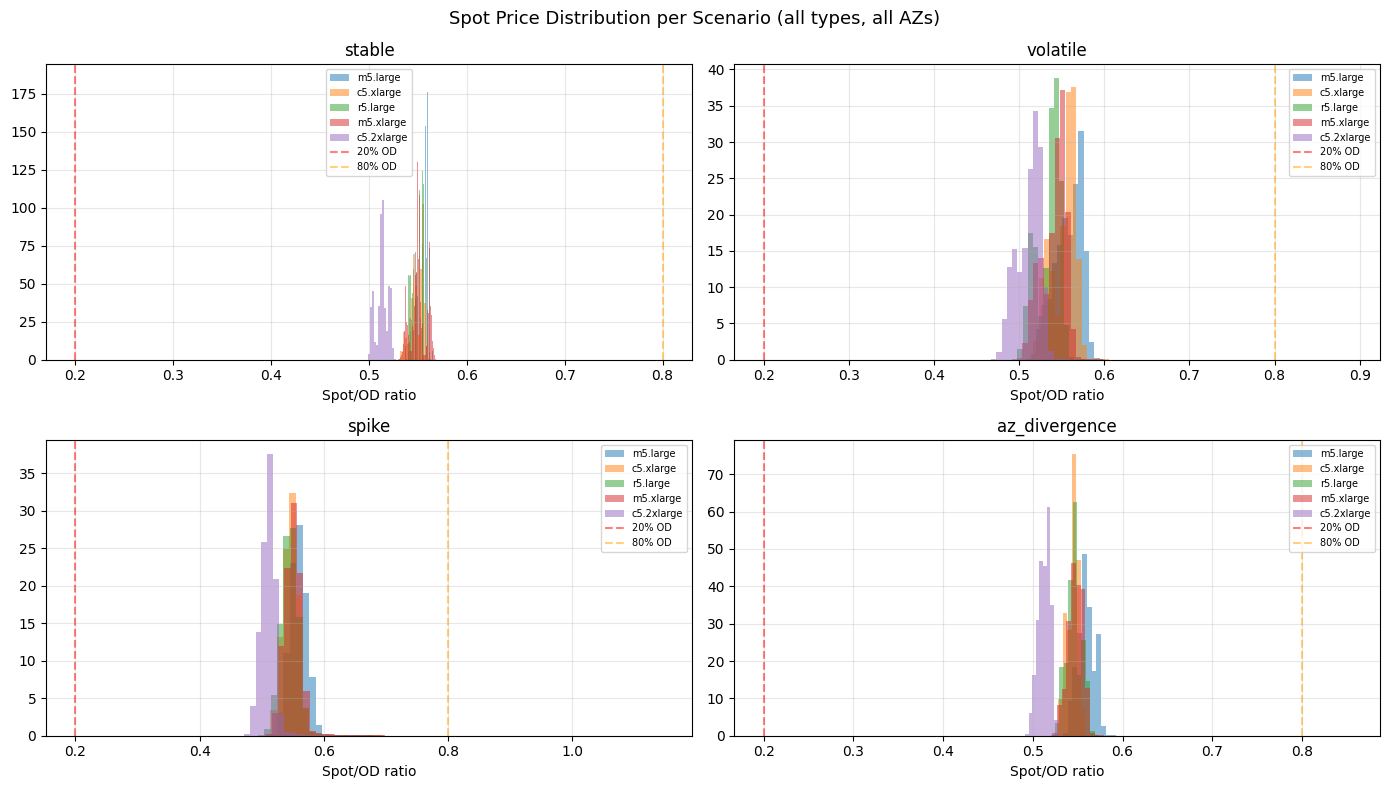

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Spot Price Distribution per Scenario (all types, all AZs)', fontsize=13)
colors = plt.cm.tab10.colors

for ax, scn in zip(axes.flat, SCENARIOS):
    df = dfs[scn]
    for i, itype in enumerate(INSTANCE_TYPES):
        sub = df[df['instance_type']==itype]['spot_price']
        od = OD_PRICES[itype]
        ax.hist(sub / od, bins=60, alpha=0.5, color=colors[i], label=itype, density=True)
    ax.axvline(0.2, color='red',   ls='--', alpha=0.5, label='20% OD')
    ax.axvline(0.8, color='orange',ls='--', alpha=0.5, label='80% OD')
    ax.set_title(scn)
    ax.set_xlabel('Spot/OD ratio')
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../data/processed/price_distribution.png', dpi=100)
plt.show()

## 6. Spot Price × Workload — 4 scenarios, 7 ngày, trục thời gian chung

**Layout:** 4 scenario (cột) × 2 panel (hàng)
- **Hàng trên:** spot price m5.large 3 AZs — đường giá thị trường
- **Hàng dưới:** workload arrivals (jobs/step 15 phút) — cùng trục thời gian

Cho thấy mối quan hệ: khi price spike → agent phải quyết định có tiếp tục dùng Spot không, trong khi workload vẫn đang đến.

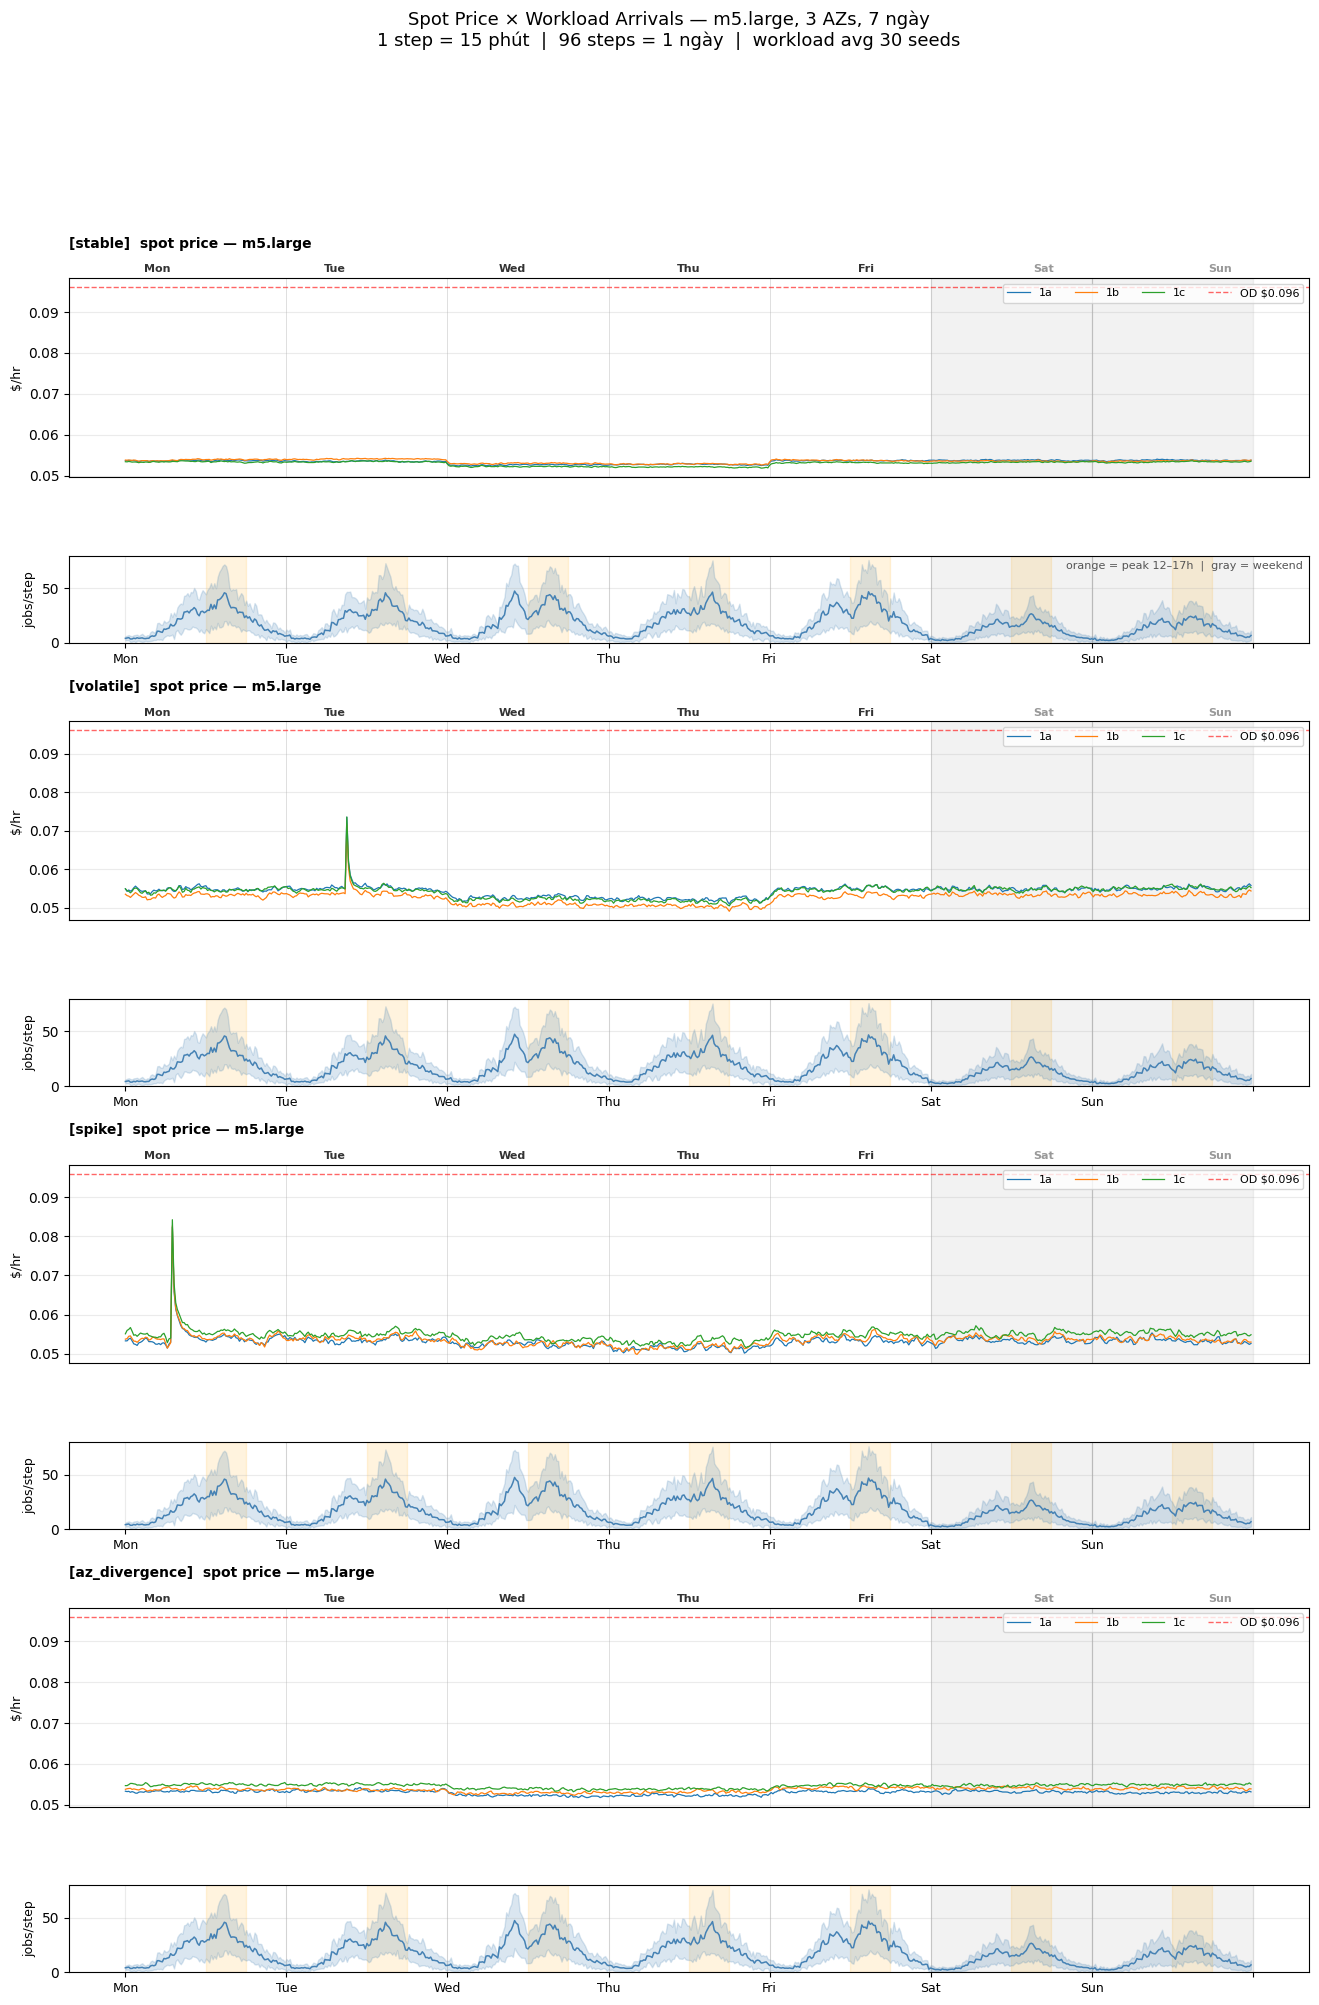

In [18]:
from envs.workload_generator import WorkloadGenerator, HOURLY_PROFILE

WORKLOAD_CFG = {
    'base_arrival_rate': 15,
    'peak_multiplier':   2.0,
    'avg_job_duration':  3,
    'weekend_factor':    0.6,
    'spike_probability': 0.02,
    'spike_multiplier':  3.0,
}
STEPS_PER_HOUR = 4
STEPS_PER_DAY  = 96
N_DAYS         = 7
N_STEPS        = N_DAYS * STEPS_PER_DAY
N_SEEDS        = 30

# ── Simulate workload ─────────────────────────────────────────────────────
arrivals = np.zeros((N_SEEDS, N_STEPS))
for seed in range(N_SEEDS):
    gen = WorkloadGenerator(**WORKLOAD_CFG, seed=seed)
    for t in range(N_STEPS):
        arrivals[seed, t] = len(gen.step())
mean_wl = arrivals.mean(axis=0)
std_wl  = arrivals.std(axis=0)

# ── Resample price → 15-min, 7 ngày đầu ──────────────────────────────────
az_colors = {
    'ap-southeast-1a': '#1f77b4',
    'ap-southeast-1b': '#ff7f0e',
    'ap-southeast-1c': '#2ca02c',
}
DAY_NAMES = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']

price_resampled = {}
for scn in SCENARIOS:
    df  = dfs[scn]
    sub = df[df['instance_type'] == 'm5.large'].sort_values('timestamp')
    t0  = sub['timestamp'].min()
    sub = sub[sub['timestamp'] < t0 + pd.Timedelta(days=N_DAYS)]
    price_resampled[scn] = {}
    for az in AZS:
        s = (sub[sub['availability_zone'] == az]
             .set_index('timestamp')['spot_price']
             .resample('15min').mean()
             .interpolate())
        price_resampled[scn][az] = s.values[:N_STEPS]

# ── Plot ──────────────────────────────────────────────────────────────────
n_scn        = len(SCENARIOS)
steps_x      = np.arange(N_STEPS)
xtick_pos    = np.arange(0, N_STEPS + 1, STEPS_PER_DAY)
xtick_labels = [DAY_NAMES[d % 7] for d in range(N_DAYS)] + ['']

fig, axes = plt.subplots(
    n_scn * 2, 1,
    figsize=(16, 22),
    gridspec_kw={'height_ratios': [1.6, 0.7] * n_scn, 'hspace': 0.55},
)
fig.suptitle(
    'Spot Price × Workload Arrivals — m5.large, 3 AZs, 7 ngày\n'
    '1 step = 15 phút  |  96 steps = 1 ngày  |  workload avg 30 seeds',
    fontsize=13, y=1.002,
)

for row, scn in enumerate(SCENARIOS):
    ax_p = axes[row * 2]
    ax_w = axes[row * 2 + 1]

    # weekend shading + day separators
    for d in range(N_DAYS):
        for ax in (ax_p, ax_w):
            if d % 7 >= 5:
                ax.axvspan(d*STEPS_PER_DAY, (d+1)*STEPS_PER_DAY,
                           alpha=0.10, color='gray', zorder=0)
            if d > 0:
                ax.axvline(d*STEPS_PER_DAY, color='black',
                           alpha=0.15, lw=0.6, zorder=1)

    # ── price panel ───────────────────────────────────────────────────────
    for az, c in az_colors.items():
        vals = price_resampled[scn].get(az, np.full(N_STEPS, np.nan))
        ax_p.plot(steps_x, vals, color=c, lw=0.9, label=az[-2:])
    ax_p.axhline(OD_PRICES['m5.large'], color='red',
                 ls='--', lw=1, alpha=0.6, label='OD $0.096')

    # title với pad đủ lớn để day labels không đè
    ax_p.set_title(f'[{scn}]  spot price — m5.large',
                   fontsize=10, fontweight='bold', loc='left', pad=22)
    ax_p.set_ylabel('$/hr', fontsize=9)
    ax_p.set_xticks([])
    ax_p.legend(fontsize=8, loc='upper right', ncol=4, framealpha=0.8)
    ax_p.grid(alpha=0.25)

    # day labels dùng axes fraction — không phụ thuộc ylim, không đè title
    for d in range(N_DAYS):
        ax_p.text(
            (d + 0.5) / N_DAYS, 1.02,
            DAY_NAMES[d % 7],
            ha='center', va='bottom', fontsize=8,
            transform=ax_p.transAxes,
            color='#999' if d % 7 >= 5 else '#333',
            fontweight='bold',
        )

    # ── workload panel ────────────────────────────────────────────────────
    ax_w.fill_between(steps_x, mean_wl - std_wl, mean_wl + std_wl,
                      alpha=0.20, color='steelblue')
    ax_w.plot(steps_x, mean_wl, color='steelblue', lw=1.1)

    for d in range(N_DAYS):
        ax_w.axvspan(d*STEPS_PER_DAY + 12*STEPS_PER_HOUR,
                     d*STEPS_PER_DAY + 18*STEPS_PER_HOUR,
                     alpha=0.13, color='orange', zorder=0)

    ax_w.set_ylabel('jobs/step', fontsize=9)
    ax_w.set_xticks(xtick_pos)
    ax_w.set_xticklabels(xtick_labels, fontsize=9)
    ax_w.set_ylim(bottom=0)
    ax_w.grid(alpha=0.25)

    if row == 0:
        ax_w.text(0.995, 0.95,
                  'orange = peak 12–17h  |  gray = weekend',
                  transform=ax_w.transAxes, fontsize=8,
                  ha='right', va='top', color='#555')

plt.savefig('../data/processed/price_workload_combined.png',
            dpi=120, bbox_inches='tight')
plt.show()

1 ngày = 96 steps (1 step = 15 phút)
base_arrival_rate = 6 jobs/step = 24 jobs/h

Daily pattern (avg over 30 seeds):
  Mean jobs/step : 6.69
  Peak jobs/step : 13.43  @ step 64 (hour 16h)
  Low  jobs/step : 1.03  @ step 7 (hour 01h)
  Total jobs/day : 642
  Peak/low ratio : 13.0×


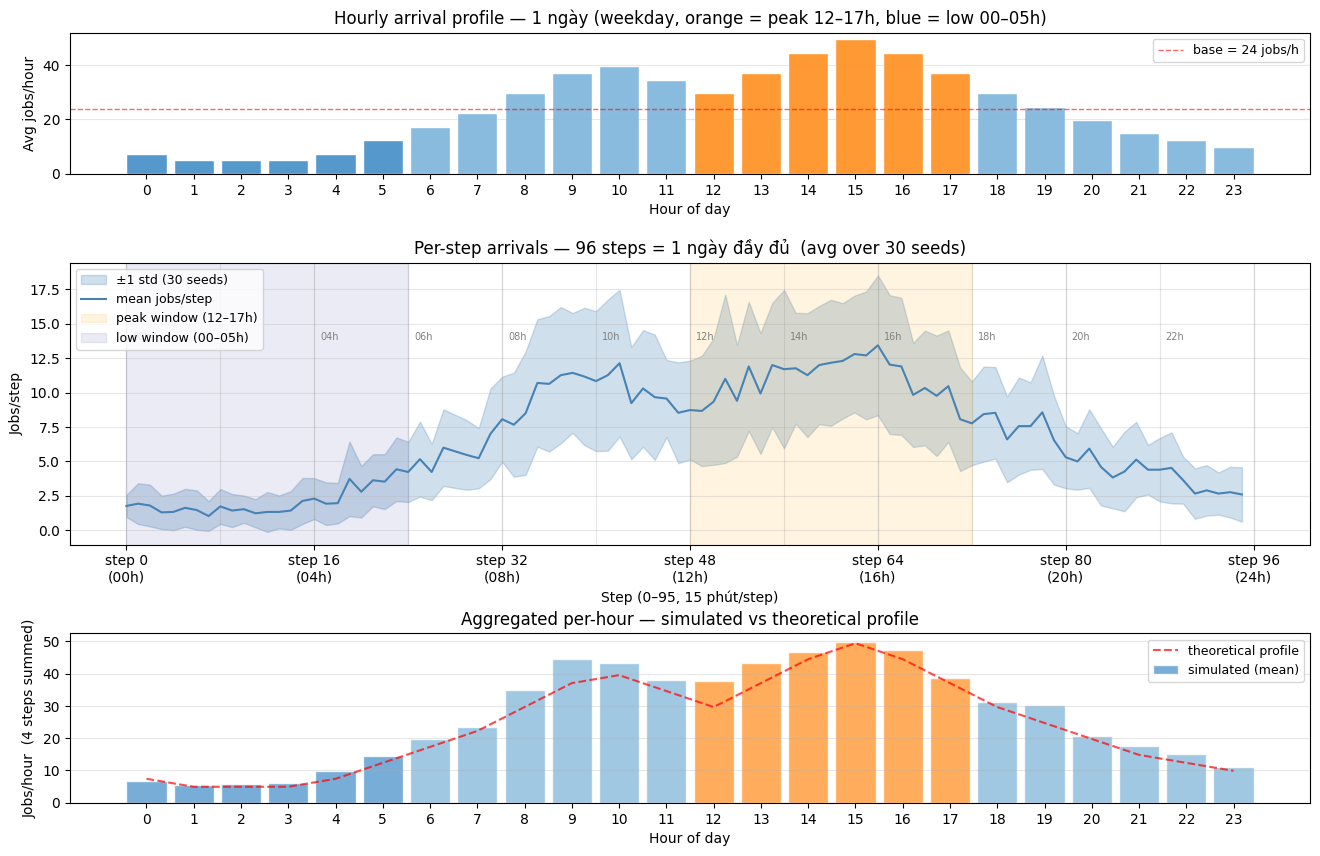

In [23]:
# Workload simulation — 1 step = 15 phút, 96 steps = 1 ngày đầy đủ
from envs.workload_generator import WorkloadGenerator, HOURLY_PROFILE

WORKLOAD_CFG = {
    'base_arrival_rate': 6,    # jobs/step (khớp kaggle_train.ipynb)
    'peak_multiplier':   1.4,
    'avg_job_duration':  3,
    'weekend_factor':    0.6,
    'spike_probability': 0.02,
    'spike_multiplier':  2.0,
}

STEPS_PER_HOUR = 4
STEPS_PER_DAY  = 96    # 24h × 4 steps/h = 1 ngày đầy đủ
N_SEEDS = 30

# Simulate đúng 1 ngày (96 steps) × N_SEEDS seeds — không có weekend/spike noise
arrivals_1day = np.zeros((N_SEEDS, STEPS_PER_DAY))
for seed in range(N_SEEDS):
    gen = WorkloadGenerator(**WORKLOAD_CFG, seed=seed)
    for t in range(STEPS_PER_DAY):
        arrivals_1day[seed, t] = len(gen.step())

mean_1day = arrivals_1day.mean(axis=0)   # [96]
std_1day  = arrivals_1day.std(axis=0)

# Hourly profile (normalized mean=1.0)
profile_norm = HOURLY_PROFILE / HOURLY_PROFILE.mean()

# ─── Stats ────────────────────────────────────────────────────────────────
print(f'1 ngày = {STEPS_PER_DAY} steps (1 step = 15 phút)')
print(f'base_arrival_rate = {WORKLOAD_CFG["base_arrival_rate"]} jobs/step '
      f'= {WORKLOAD_CFG["base_arrival_rate"] * STEPS_PER_HOUR} jobs/h')
print()
print(f'Daily pattern (avg over {N_SEEDS} seeds):')
print(f'  Mean jobs/step : {mean_1day.mean():.2f}')
print(f'  Peak jobs/step : {mean_1day.max():.2f}  @ step {mean_1day.argmax()} '
      f'(hour {mean_1day.argmax() // STEPS_PER_HOUR:02d}h)')
print(f'  Low  jobs/step : {mean_1day.min():.2f}  @ step {mean_1day.argmin()} '
      f'(hour {mean_1day.argmin() // STEPS_PER_HOUR:02d}h)')
print(f'  Total jobs/day : {mean_1day.sum():.0f}')
print(f'  Peak/low ratio : {mean_1day.max() / mean_1day.min():.1f}×')

# ─── Plot 3 panels ─────────────────────────────────────────────────────────
fig = plt.figure(figsize=(16, 10))
gs = gridspec.GridSpec(3, 1, height_ratios=[1, 2, 1.2], hspace=0.45)

# ── Panel 1: Hourly profile bar (24 giờ)
ax1 = fig.add_subplot(gs[0])
hours = np.arange(24)
rates_per_hour = WORKLOAD_CFG['base_arrival_rate'] * profile_norm * STEPS_PER_HOUR
bar_colors = ['#ff9933' if (12 <= h <= 17) else
              '#5599cc' if (0  <= h <= 5)  else
              '#88bbdd' for h in hours]
ax1.bar(hours, rates_per_hour, color=bar_colors, edgecolor='white', width=0.85)
ax1.axhline(WORKLOAD_CFG['base_arrival_rate'] * STEPS_PER_HOUR,
            color='red', ls='--', lw=1, alpha=0.6,
            label=f'base = {WORKLOAD_CFG["base_arrival_rate"] * STEPS_PER_HOUR} jobs/h')
ax1.set_xticks(hours)
ax1.set_xlabel('Hour of day')
ax1.set_ylabel('Avg jobs/hour')
ax1.set_title('Hourly arrival profile — 1 ngày (weekday, orange = peak 12–17h, blue = low 00–05h)')
ax1.legend(fontsize=9)
ax1.grid(alpha=0.3, axis='y')

# ── Panel 2: Per-step (15-min) arrivals — 96 steps = 1 ngày đầy đủ
ax2 = fig.add_subplot(gs[1])
steps = np.arange(STEPS_PER_DAY)
ax2.fill_between(steps,
                 mean_1day - std_1day,
                 mean_1day + std_1day,
                 alpha=0.25, color='steelblue',
                 label=f'±1 std ({N_SEEDS} seeds)')
ax2.plot(steps, mean_1day, color='steelblue', lw=1.5, label='mean jobs/step')

# Hour grid lines + labels
for h in range(0, 25, 2):
    x = h * STEPS_PER_HOUR
    if x <= STEPS_PER_DAY:
        ax2.axvline(x, color='gray', alpha=0.2, lw=0.8)
        if h < 24:
            ax2.text(x + 0.5, mean_1day.max() * 1.02,
                     f'{h:02d}h', fontsize=7, color='gray', va='bottom')

# Peak window shading
ax2.axvspan(12 * STEPS_PER_HOUR, 18 * STEPS_PER_HOUR,
            alpha=0.12, color='orange', label='peak window (12–17h)')
ax2.axvspan(0, 6 * STEPS_PER_HOUR,
            alpha=0.08, color='navy',   label='low window (00–05h)')

ax2.set_xlabel('Step (0–95, 15 phút/step)')
ax2.set_ylabel('Jobs/step')
ax2.set_title(f'Per-step arrivals — 96 steps = 1 ngày đầy đủ  (avg over {N_SEEDS} seeds)')
ax2.set_xticks(np.arange(0, STEPS_PER_DAY + 1, STEPS_PER_HOUR * 4))   # every 4h
ax2.set_xticklabels([f'step {s}\n({s // STEPS_PER_HOUR:02d}h)' for s in range(0, STEPS_PER_DAY + 1, 16)])
ax2.legend(fontsize=9, loc='upper left')
ax2.grid(alpha=0.3)

# ── Panel 3: Aggregated per-hour (24 bars) — 4 steps summed → 1 bar
ax3 = fig.add_subplot(gs[2])
per_hour_sim = mean_1day.reshape(24, STEPS_PER_HOUR).sum(axis=1)   # sum 4 steps → 1 hour
ax3.bar(hours, per_hour_sim, color=bar_colors, edgecolor='white', width=0.85, alpha=0.8,
        label='simulated (mean)')
ax3.plot(hours, rates_per_hour, 'r--', lw=1.5, alpha=0.7, label='theoretical profile')
ax3.set_xticks(hours)
ax3.set_xlabel('Hour of day')
ax3.set_ylabel('Jobs/hour  (4 steps summed)')
ax3.set_title('Aggregated per-hour — simulated vs theoretical profile')
ax3.legend(fontsize=9)
ax3.grid(alpha=0.3, axis='y')

plt.savefig('../data/processed/workload_96steps_daily.png', dpi=100, bbox_inches='tight')
plt.show()

=== CAPACITY DEPTH & INTERRUPT PROB ===

stable:
  capacity_depth: mean=0.770  min=0.043  p5=0.505  p95=1.000
  near_zero (<0.1): 0.0%  (high interrupt risk)

volatile:
  capacity_depth: mean=0.746  min=0.000  p5=0.446  p95=1.000
  near_zero (<0.1): 0.1%  (high interrupt risk)

spike:
  capacity_depth: mean=0.718  min=0.000  p5=0.357  p95=1.000
  near_zero (<0.1): 0.7%  (high interrupt risk)

az_divergence:
  capacity_depth: mean=0.749  min=0.000  p5=0.451  p95=1.000
  near_zero (<0.1): 0.1%  (high interrupt risk)


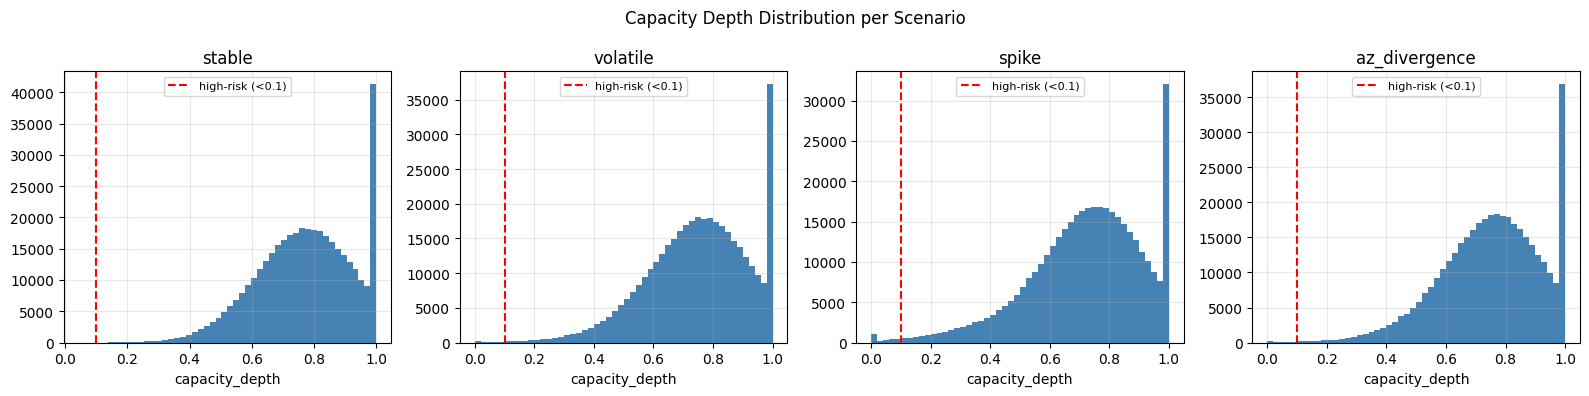

In [20]:
print('=== CAPACITY DEPTH & INTERRUPT PROB ===')
for scn in SCENARIOS:
    df = dfs[scn]
    cap = df['capacity_depth']
    iprob = df['est_interruption_prob'] if 'est_interruption_prob' in df.columns else None
    print(f'\n{scn}:')
    print(f'  capacity_depth: mean={cap.mean():.3f}  min={cap.min():.3f}  p5={cap.quantile(0.05):.3f}  p95={cap.quantile(0.95):.3f}')
    print(f'  near_zero (<0.1): {(cap < 0.1).mean():.1%}  (high interrupt risk)')
    if iprob is not None:
        print(f'  interrupt_prob: mean={iprob.mean():.3f}  max={iprob.max():.3f}')

# Plot capacity depth distribution
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle('Capacity Depth Distribution per Scenario', fontsize=12)
for ax, scn in zip(axes, SCENARIOS):
    dfs[scn]['capacity_depth'].hist(ax=ax, bins=50, color='steelblue', edgecolor='none')
    ax.axvline(0.1, color='red', ls='--', label='high-risk (<0.1)')
    ax.set_title(scn)
    ax.set_xlabel('capacity_depth')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Cross-type price spread — agent nên học chọn cheapest type

=== VCPU-NORMALIZED PRICE ($/vCPU/hr) — thứ tự cheapest ===

stable — mean spot price per vCPU:
  c5.2xlarge  : $0.1746/hr  $0.0218/vCPU  (OD: $0.340)
  c5.xlarge   : $0.0933/hr  $0.0233/vCPU  (OD: $0.170)
  m5.xlarge   : $0.1057/hr  $0.0264/vCPU  (OD: $0.192)
  m5.large    : $0.0533/hr  $0.0266/vCPU  (OD: $0.096)
  r5.large    : $0.0694/hr  $0.0347/vCPU  (OD: $0.126)


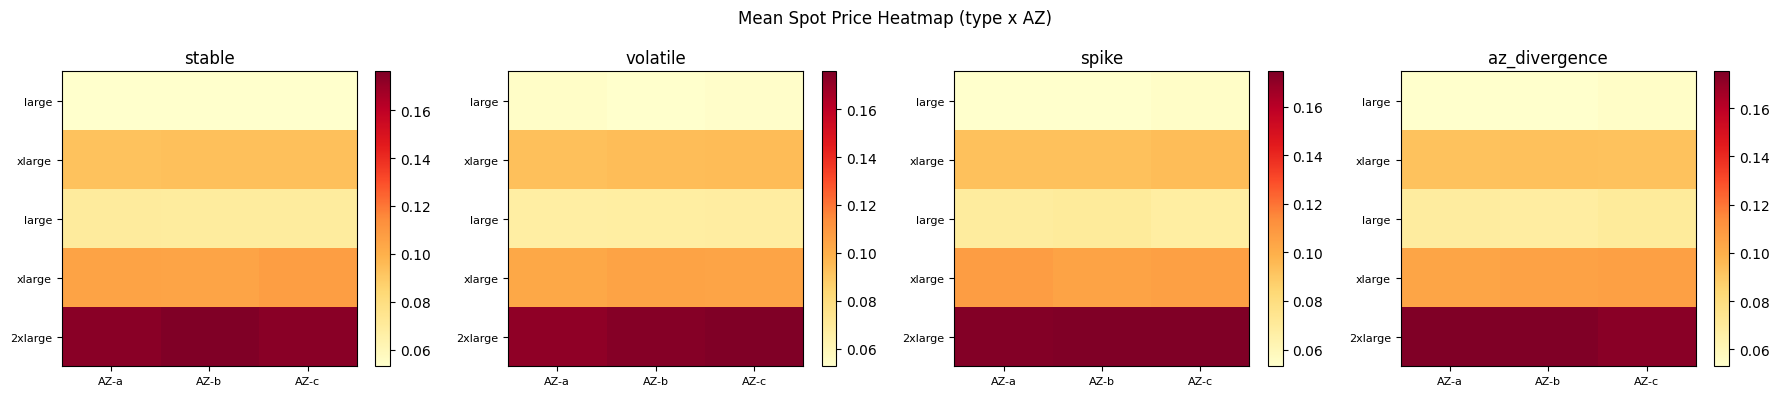

In [21]:
print('=== VCPU-NORMALIZED PRICE ($/vCPU/hr) — thứ tự cheapest ===')
VCPUS = {'m5.large': 2, 'c5.xlarge': 4, 'r5.large': 2, 'm5.xlarge': 4, 'c5.2xlarge': 8}

for scn in ['stable']:
    df = dfs[scn]
    print(f'\n{scn} — mean spot price per vCPU:')
    rows = []
    for itype in INSTANCE_TYPES:
        mean_p = df[df['instance_type']==itype]['spot_price'].mean()
        per_vcpu = mean_p / VCPUS[itype]
        rows.append((itype, mean_p, per_vcpu))
    for itype, p, pv in sorted(rows, key=lambda x: x[2]):
        print(f'  {itype:12s}: ${p:.4f}/hr  ${pv:.4f}/vCPU  (OD: ${OD_PRICES[itype]:.3f})')

# Heatmap: mean spot price per (type, AZ) for each scenario
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
fig.suptitle('Mean Spot Price Heatmap (type x AZ)', fontsize=12)

for ax, scn in zip(axes, SCENARIOS):
    matrix = []
    for itype in INSTANCE_TYPES:
        row = []
        for az in AZS:
            val = dfs[scn][(dfs[scn]['instance_type']==itype) & (dfs[scn]['availability_zone']==az)]['spot_price'].mean()
            row.append(val)
        matrix.append(row)
    im = ax.imshow(matrix, aspect='auto', cmap='YlOrRd')
    ax.set_xticks(range(3)); ax.set_xticklabels(['AZ-a','AZ-b','AZ-c'], fontsize=8)
    ax.set_yticks(range(5)); ax.set_yticklabels([t.split('.')[1] for t in INSTANCE_TYPES], fontsize=8)
    ax.set_title(scn)
    plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.savefig('../data/processed/price_heatmap.png', dpi=100)
plt.show()

## 9. Summary — Pass/Fail checklist

In [22]:
print('=' * 55)
print('DATA QUALITY CHECKLIST')
print('=' * 55)

all_pass = True
checks = []

for scn in SCENARIOS:
    df = dfs[scn].copy()
    df['od'] = df['instance_type'].map(OD_PRICES)
    df['ratio'] = df['spot_price'] / df['od']

    # Check 1: row count
    expected = len(INSTANCE_TYPES) * len(AZS)
    actual_pools = df.groupby(['instance_type','availability_zone']).ngroups
    c1 = actual_pools == expected

    # Check 2: spot/OD ratio 15-85%
    c2 = (df['ratio'].mean() >= 0.15) and (df['ratio'].mean() <= 0.85)

    # Check 3: no negative or zero prices
    c3 = (df['spot_price'] > 0).all()

    # Check 4: spike rate < 3%
    jumps = df.groupby(['instance_type','availability_zone'])['spot_price'].pct_change().abs()
    spike_rate = (jumps > 0.15).mean()
    c4 = spike_rate < 0.03

    # Check 5: capacity_depth in [0,1]
    c5 = (df['capacity_depth'] >= 0).all() and (df['capacity_depth'] <= 1).all()

    # Check 6: AZ correlation reasonable
    pivot = df[df['instance_type']=='m5.large'].pivot_table(
        index='timestamp', columns='availability_zone', values='spot_price')
    avg_corr = pivot.corr().values[np.triu_indices(3, k=1)].mean()
    c6 = (avg_corr > 0.1) and (avg_corr < 0.99)

    results = [c1, c2, c3, c4, c5, c6]
    labels  = ['15 pools', 'ratio 15-85%', 'no zero price', 'spike<3%', 'cap_depth [0,1]', 'AZ corr ok']
    passed  = all(results)
    all_pass = all_pass and passed

    status = 'PASS' if passed else 'FAIL'
    print(f'\n[{status}] {scn}')
    for label, ok in zip(labels, results):
        mark = 'OK' if ok else 'FAIL'
        extra = ''
        if label == 'ratio 15-85%': extra = f' (mean={df["ratio"].mean():.1%})'
        if label == 'spike<3%':     extra = f' ({spike_rate:.2%}/step)'
        if label == 'AZ corr ok':   extra = f' (avg={avg_corr:.2f})'
        print(f'  [{mark}] {label}{extra}')

print('\n' + '=' * 55)
print('OVERALL:', 'ALL PASS - Data ready for training!' if all_pass else 'SOME CHECKS FAILED - Review above')
print('=' * 55)

DATA QUALITY CHECKLIST

[PASS] stable
  [OK] 15 pools
  [OK] ratio 15-85% (mean=54.4%)
  [OK] no zero price
  [OK] spike<3% (0.00%/step)
  [OK] cap_depth [0,1]
  [OK] AZ corr ok (avg=0.90)

[PASS] volatile
  [OK] 15 pools
  [OK] ratio 15-85% (mean=54.0%)
  [OK] no zero price
  [OK] spike<3% (0.03%/step)
  [OK] cap_depth [0,1]
  [OK] AZ corr ok (avg=0.96)

[PASS] spike
  [OK] 15 pools
  [OK] ratio 15-85% (mean=54.4%)
  [OK] no zero price
  [OK] spike<3% (0.09%/step)
  [OK] cap_depth [0,1]
  [OK] AZ corr ok (avg=0.95)

[PASS] az_divergence
  [OK] 15 pools
  [OK] ratio 15-85% (mean=54.2%)
  [OK] no zero price
  [OK] spike<3% (0.02%/step)
  [OK] cap_depth [0,1]
  [OK] AZ corr ok (avg=0.83)

OVERALL: ALL PASS - Data ready for training!
